In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

orders = pd.read_csv("../data/clean/order_summary.csv")
items  = pd.read_csv("../data/clean/item_summary.csv")

window = ["2018-04", "2018-05", "2018-06", "2018-07", "2018-08"]

print(orders.shape, items.shape)

(99441, 12) (112650, 13)


  purchase_month     revenue  orders     aov
0        2018-04  1156248.89    6919  167.11
1        2018-05  1145686.46    6833  167.67
2        2018-06  1020381.90    6145  166.05
3        2018-07  1039783.58    6233  166.82
4        2018-08   996973.51    6421  155.27


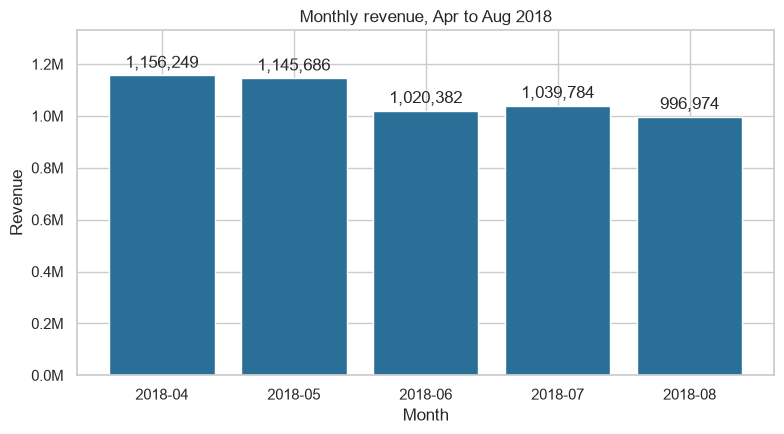

In [14]:
valid = orders[(orders["is_valid"] == 1)
               & (orders["revenue"].notna())
               & (orders["purchase_month"].isin(window))]

monthly = valid.groupby("purchase_month").agg(
    revenue=("revenue", "sum"),
    orders=("order_id", "nunique")).reset_index()
monthly["aov"] = monthly["revenue"] / monthly["orders"]
print(monthly.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(monthly["purchase_month"], monthly["revenue"], color="#2a6f97")
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in monthly["revenue"]], padding=3)
ax.set_ylim(0, monthly["revenue"].max() * 1.15)
ax.yaxis.set_major_formatter(lambda x, pos: f"{x/1e6:.1f}M")
ax.set_title("Monthly revenue, Apr to Aug 2018")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue")
plt.tight_layout()
plt.savefig("../images/01_monthly_revenue.png", dpi=150)
plt.show()

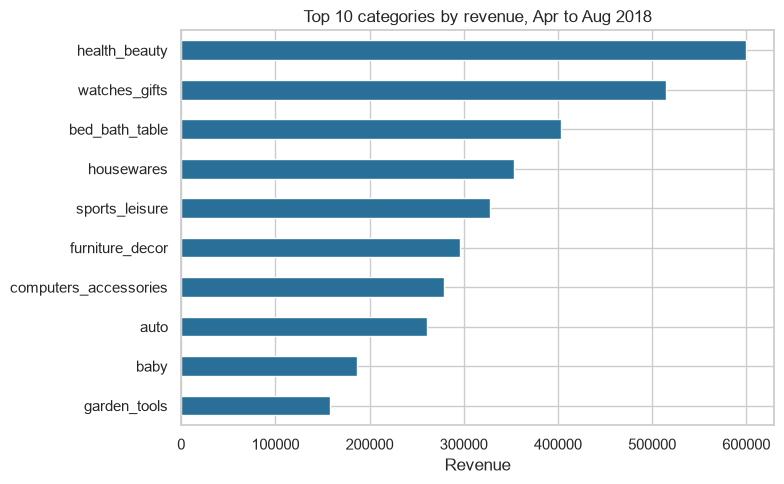

In [3]:
v = items[(items["is_valid"] == 1) & (items["purchase_month"].isin(window))]

top10 = (v.groupby("category")["revenue"].sum()
          .sort_values(ascending=False).head(10).sort_values())

fig, ax = plt.subplots(figsize=(8, 5))
top10.plot(kind="barh", color="#2a6f97", ax=ax)
ax.set_title("Top 10 categories by revenue, Apr to Aug 2018")
ax.set_xlabel("Revenue")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../images/02_top_categories.png", dpi=150)
plt.show()

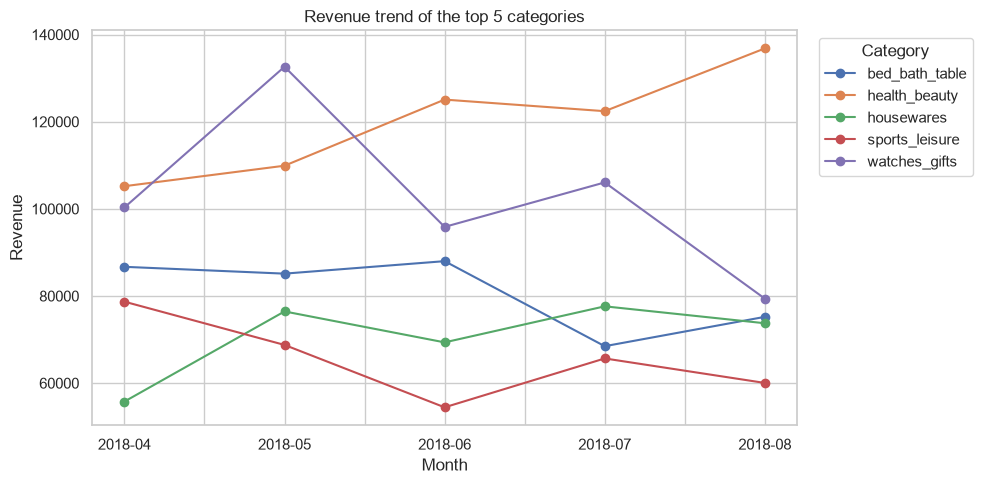

In [5]:
top5 = top10.sort_values(ascending=False).head(5).index

trend = (v[v["category"].isin(top5)]
         .pivot_table(index="purchase_month", columns="category",
                      values="revenue", aggfunc="sum"))

ax = trend.plot(marker="o", figsize=(10, 5))
ax.set_title("Revenue trend of the top 5 categories")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue")
ax.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("../images/03_category_trends.png", dpi=150, bbox_inches="tight")
plt.show()

review_score
1    10.75
2     3.12
3     8.26
4    19.49
5    58.38
Name: proportion, dtype: float64


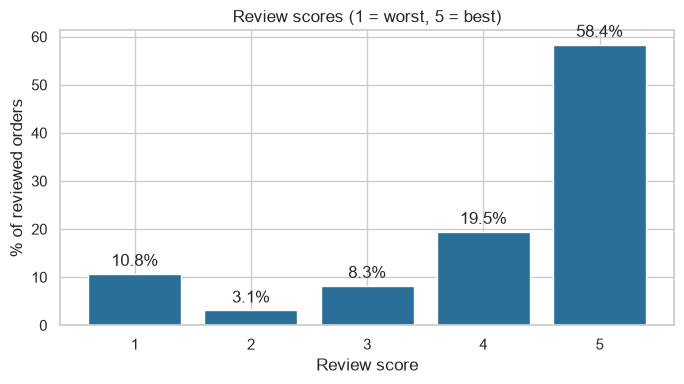

In [6]:
dist = (orders[orders["is_valid"] == 1]["review_score"]
        .dropna().astype(int).value_counts(normalize=True).sort_index() * 100)
print(dist.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(dist.index.astype(str), dist.values, color="#2a6f97")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_title("Review scores (1 = worst, 5 = best)")
ax.set_xlabel("Review score")
ax.set_ylabel("% of reviewed orders")
plt.tight_layout()
plt.savefig("../images/04_review_distribution.png", dpi=150)
plt.show()

         count  mean
status              
Late      6381  2.27
On time  89443  4.29


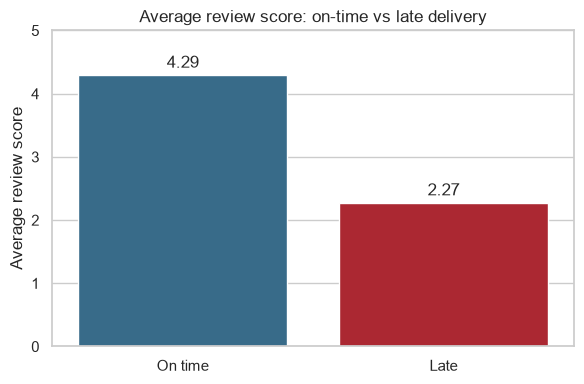

In [13]:
d = orders[orders["is_late"].notna()].copy()
d["status"] = d["is_late"].map({0: "On time", 1: "Late"})

print(d.groupby("status")["review_score"].agg(["count", "mean"]).round(2))

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=d, x="status", y="review_score",
            order=["On time", "Late"], errorbar=None,
            palette=["#2a6f97", "#c1121f"], hue="status", legend=False, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.bar_label(ax.containers[1], fmt="%.2f", padding=3)
ax.set_ylim(0, 5)
ax.set_title("Average review score: on-time vs late delivery")
ax.set_xlabel("")
ax.set_ylabel("Average review score")
plt.tight_layout()
plt.savefig("../images/05_late_vs_ontime.png", dpi=150)
plt.show()

             count  mean
time_bucket             
0-7          30550  4.41
8-14         37775  4.30
15-21        16054  4.12
22-28         6311  3.62
29+           5134  2.37


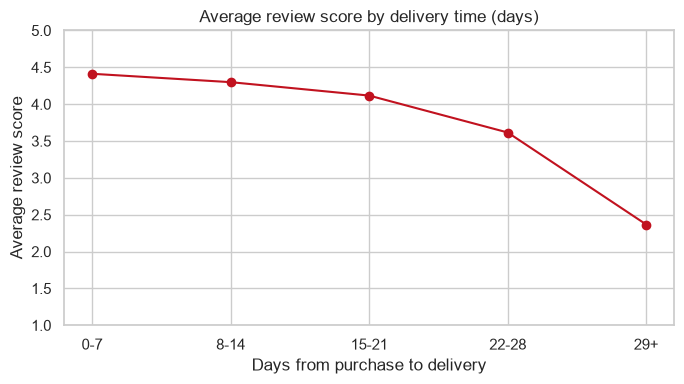

In [9]:
d["time_bucket"] = pd.cut(d["delivery_days"],
                          bins=[-1, 7, 14, 21, 28, 1000],
                          labels=["0-7", "8-14", "15-21", "22-28", "29+"])

by_bucket = d.groupby("time_bucket", observed=True)["review_score"].agg(["count", "mean"])
print(by_bucket.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(by_bucket.index.astype(str), by_bucket["mean"], marker="o", color="#c1121f")
ax.set_ylim(1, 5)
ax.set_title("Average review score by delivery time (days)")
ax.set_xlabel("Days from purchase to delivery")
ax.set_ylabel("Average review score")
plt.tight_layout()
plt.savefig("../images/06_review_by_delivery_days.png", dpi=150)
plt.show()

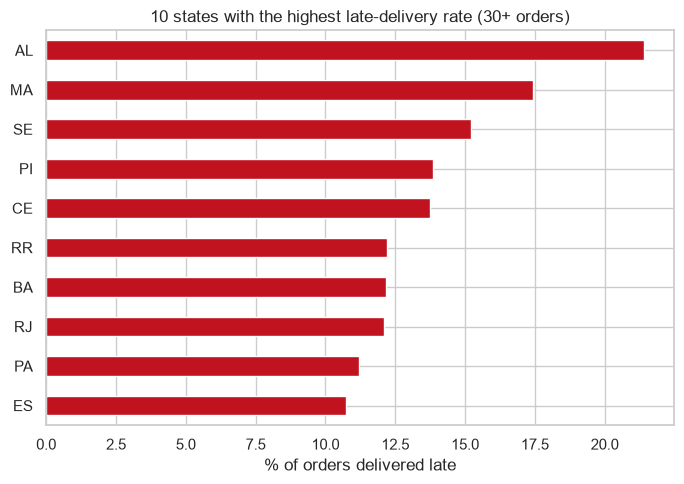

In [10]:
states = d.groupby("customer_state").agg(
    orders=("order_id", "count"),
    late_rate=("is_late", "mean"))
states = states[states["orders"] >= 30]
states["late_rate"] = states["late_rate"] * 100
worst = states.sort_values("late_rate", ascending=False).head(10).sort_values("late_rate")

fig, ax = plt.subplots(figsize=(7, 5))
worst["late_rate"].plot(kind="barh", color="#c1121f", ax=ax)
ax.set_title("10 states with the highest late-delivery rate (30+ orders)")
ax.set_xlabel("% of orders delivered late")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../images/07_late_rate_by_state.png", dpi=150)
plt.show()

In [11]:
%pip install scipy

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
    --------------------------------------- 0.5/37.4 MB 3.0 MB/s eta 0:00:13
   - -------------------------------------- 1.0/37.4 MB 2.6 MB/s eta 0:00:14
   - -------------------------------------- 1.0/37.4 MB 2.6 MB/s eta 0:00:14
   -- ------------------------------------- 2.1/37.4 MB 2.6 MB/s eta 0:00:14
   --- ------------------------------------ 2.9/37.4 MB 3.1 MB/s eta 0:00:12
   ---- ----------------------------------- 3.9/37.4 MB 3.3 MB/s eta 0:00:11
   ----- ---------------------------------- 5.5/37.4 MB 3.9 MB/s eta 0:00:09
   ------ --------------------------------- 6.3/37.4 MB 3.9 MB/s eta 0:00:08
   -------- --------------

In [12]:
pair = d[["delivery_days", "review_score"]].dropna()
corr = pair.corr(method="spearman").loc["delivery_days", "review_score"]
print("Correlation between delivery days and review score:", round(corr, 3))

print("\nDelivery days, summary:")
print(d["delivery_days"].describe().round(1))

Correlation between delivery days and review score: -0.235

Delivery days, summary:
count    96470.0
mean        12.5
std          9.6
min          0.0
25%          7.0
50%         10.0
75%         16.0
max        210.0
Name: delivery_days, dtype: float64
